# PRG Toolbox Tutorial: Momentum-Space Coarse Graining

The real-space PRG used in the other notebooks merges pairs of maximally correlated variables, building clusters of $2, 4, \dots, 2^k$ units. The **momentum-space** coarse graining, introduced alongside it by [Meshulam et al. (2019)](https://doi.org/10.1103/PhysRevLett.123.178103) and analyzed in detail by [Nicoletti et al. (2020)](https://journals.aps.org/prresearch/abstract/10.1103/PhysRevResearch.2.023144), takes a complementary route: instead of grouping units, it removes the *fine-grained modes* of the population activity.

In a physical system with translation invariance, the eigenvectors of the covariance matrix are Fourier modes, and their eigenvalues decrease with the wave number (momentum). The usual momentum-space RG integrates out the high-momentum (short-wavelength) modes. For neural populations there is no lattice, but the analogy still holds if we order the principal components by their variance: the modes with the largest eigenvalues play the role of the long-wavelength, collective fluctuations, and the ones with the smallest eigenvalues the role of the fine details.

Starting from the mean-subtracted activity $\delta x_j = x_j - \langle x_j \rangle$ of $N$ units, and the covariance eigenvectors $u_\mu$ ordered by decreasing eigenvalue $\lambda_\mu$, each unit is projected onto the $K$ leading modes and rescaled to unit variance:

$$\phi_i^{(K)} = z_i \sum_{j=1}^{N} \sum_{\mu=1}^{K} u_{i\mu}\, u_{j\mu}\, \delta x_j \quad ,$$

where $z_i$ is chosen so that $\langle (\phi_i^{(K)})^2 \rangle = 1$. At coarse-graining step $k$ we keep $K = N/2^k$ modes. Step $k = 0$ (all modes kept) just returns the z-scored original activity.

**The question we ask:** as we discard more and more fine-grained modes, does the distribution $P(\phi)$ approach a Gaussian, as the central limit theorem predicts for independent units, or does it converge to a non-Gaussian form?

In this notebook we will:
1. Run the momentum-space coarse graining with `MSVariables` and look at what it does to the data.
2. Compute and plot the distribution of the coarse-grained variables with `momentum_space_distribution`.
3. Compare it with a null model in which units are independent.
4. Put it side by side with the real-space activity distribution.

---

### First, let's load some data

As in *but_what_does_PRG_do.ipynb*, we use simulated spiking activity of the V4 layer-5E excitatory population of the multi-area model of [Schmidt et al. (2018)](https://doi.org/10.1371/journal.pcbi.1006359), binarized in 5 ms bins. To keep the notebook fast, we take a random sample of 1024 neurons.

In [1]:
import prg_toolbox as prg
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kurtosis

# Download spiking data (only the first time) and return the path to the file
file_path = prg.datasets.get_spike_data(files=['5E'])

# Load the spike timestamps and keep a random sample of 1024 neurons
data_format = 'tabular'
data_timestamps = prg.tools._load_timestamps(file_path, format=data_format)
timestamps = prg.tools._pick_random_sample_from_timestamps(data_timestamps, sample_size=1024)
del data_timestamps  # free memory, the full file is no longer needed

binary_array = prg.tools.binarize_data(timestamps, data_format=data_format, binsize_ms=5)
print(f'{binary_array.shape[0]} neurons, {binary_array.shape[1]} time bins')

✔ Ready: /home/shimoura/Github/prg_toolbox/example_notebooks/example_data_directory/spikes-V4-5E.gdf


1024 neurons, 10100 time bins


### Running the momentum-space coarse graining

`MSVariables` plays the same role as `CGVariables` does for the real-space PRG: it takes the data array and the number of coarse-graining steps. Here, with $N = 1024$ and 8 steps, we keep $K = 1024, 512, \dots, 4$ modes.

Two differences from `CGVariables` are worth keeping in mind:
- The number of variables does **not** shrink: every step still has one variable per neuron, now built from fewer modes.
- Because of that, storing every step would take `rg_steps + 1` copies of the data. `MSVariables` stores only the eigendecomposition and computes the variables of a step on demand with `get_MS_variables(k)`.

The input does not need to be binary: continuous signals (e.g. calcium traces or BOLD) can be passed directly.

In [2]:
rg_steps = 8
MS_variables = prg.MSVariables(binary_array, rg_steps=rg_steps)

print('Modes kept at each step (K):', MS_variables.cutoffs)
print('Attributes:', list(MS_variables.__dict__.keys()))

Modes kept at each step (K): [1024  512  256  128   64   32   16    8    4]
Attributes: ['verbose', 'rg_steps', 'time_window', 'original_idx', 'cutoffs', 'eigenvalues', 'eigenvectors', '_centered_data']


#### Which modes are being kept?

The covariance spectrum shows what we discard at each step. The dashed lines mark the cutoffs $K = N/2^k$: at every step, all modes to the right of the line are removed. The right panel shows the fraction of the total variance carried by the modes we keep.

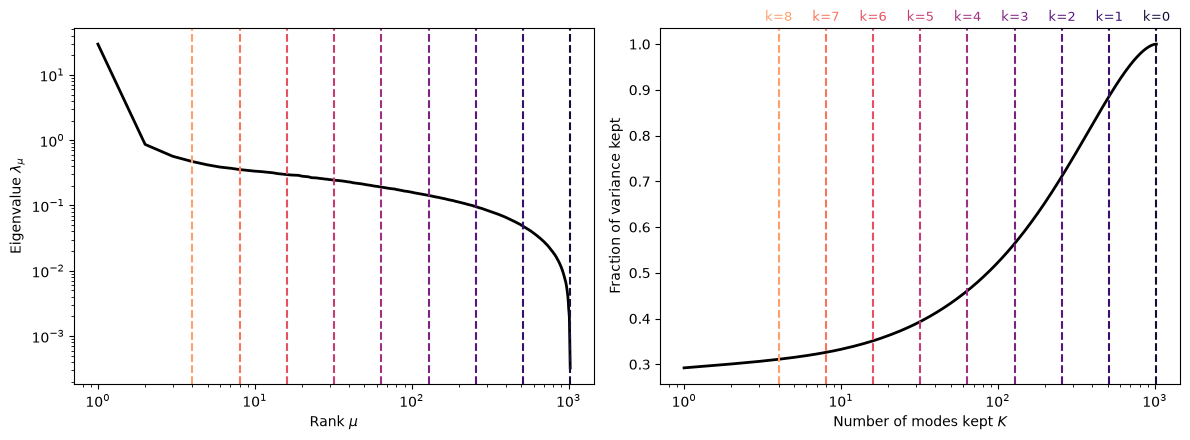

In [3]:
eigenvalues = MS_variables.eigenvalues
rank = np.arange(1, len(eigenvalues) + 1)
variance_kept = np.cumsum(eigenvalues) / np.sum(eigenvalues)
step_colors = plt.get_cmap('magma')(np.linspace(0.1, 0.8, rg_steps + 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].loglog(rank, eigenvalues, color='k', lw=2)
axes[0].set_xlabel('Rank $\\mu$')
axes[0].set_ylabel('Eigenvalue $\\lambda_\\mu$')

axes[1].semilogx(rank, variance_kept, color='k', lw=2)
axes[1].set_xlabel('Number of modes kept $K$')
axes[1].set_ylabel('Fraction of variance kept')

for k, K in enumerate(MS_variables.cutoffs):
    for ax in axes:
        ax.axvline(K, color=step_colors[k], ls='--', lw=1.5)
    axes[1].annotate(f'k={k}', (K, 1.02), color=step_colors[k], ha='center', fontsize=9,
                     xycoords=('data', 'axes fraction'))
plt.tight_layout()
plt.show()

#### What happens to a single neuron?

At $k = 0$ the coarse-grained variable is the z-scored spike train of the neuron. As we remove fine-grained modes, $\phi_i$ keeps only the part of the neuron's activity that is shared with the large-scale (high-variance) fluctuations of the population, and turns into a smooth signal that tracks collective events.

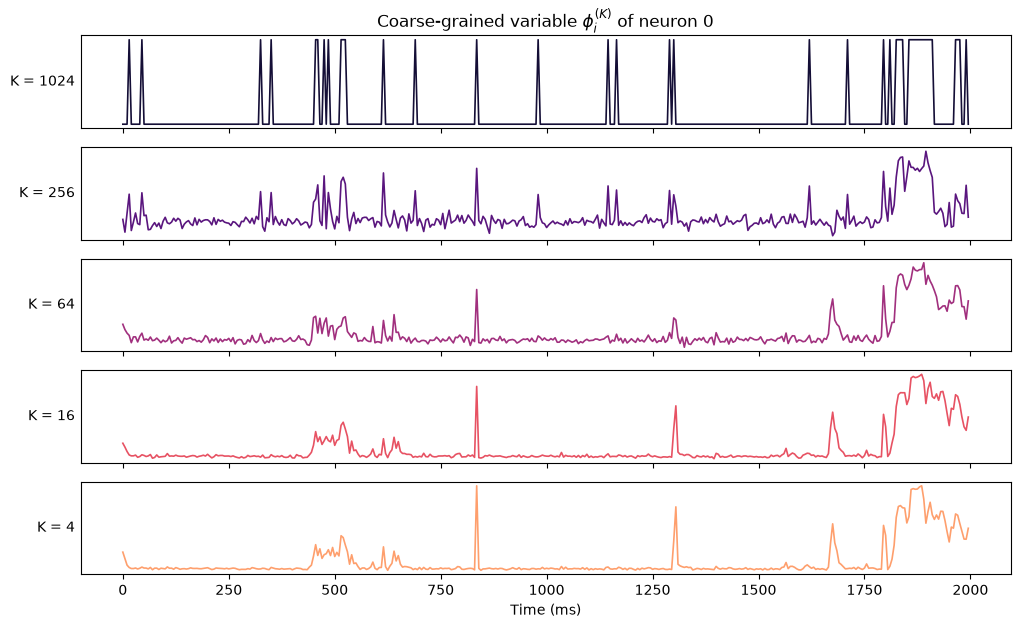

In [4]:
neuron = 0
time_ms = np.arange(400) * 5  # first 2 s, 5 ms bins
steps_to_show = [0, 2, 4, 6, 8]

fig, axes = plt.subplots(len(steps_to_show), 1, figsize=(12, 7), sharex=True)
for ax, k in zip(axes, steps_to_show):
    phi = MS_variables.get_MS_variables(k)[neuron, :len(time_ms)]
    ax.plot(time_ms, phi, color=step_colors[k], lw=1.2)
    ax.set_ylabel(f'K = {MS_variables.cutoffs[k]}', rotation=0, ha='right', va='center')
    ax.set_yticks([])
axes[-1].set_xlabel('Time (ms)')
axes[0].set_title(f'Coarse-grained variable $\\phi_i^{{(K)}}$ of neuron {neuron}')
plt.show()

### The distribution of the coarse-grained variables

`momentum_space_distribution` pools the values of all variables at each step and estimates their probability density. Like the other observables, it takes the coarse-graining object as input.

The histogram uses the same bin edges at every step (by default, 200 bins over $[-10, 10]$), so that all curves are directly comparable. Spiking data has long positive tails (a burst of collective activity is a large positive fluctuation), so here we widen the range. If some values fall outside the bins, the observable warns about it instead of silently renormalizing the density.

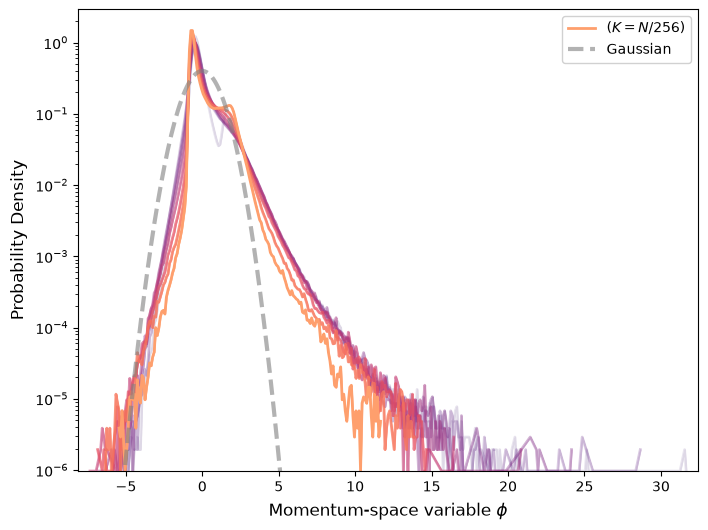

In [5]:
bins = np.linspace(-10, 45, 551)
MS_distribution = prg.momentum_space_distribution(MS_variables, bins=bins)

fig = plt.figure(figsize=(8, 6))
prg.plot.plot_momentum_space_distribution(MS_distribution)
plt.show()

The curves go from the lighter (transparent) ones, with many modes, to the opaque orange one, with only $K = N/256 = 4$ modes. The gray dashed line is the standard normal distribution: since every $\phi_i$ has zero mean and unit variance, this is exactly the Gaussian reference, with no fitted parameters.

The distributions stay far from Gaussian as we remove modes: a sharp peak at slightly negative values (silent periods) and a heavy, roughly exponential tail of positive values (collective bursts).

### Comparison with a null model

Is this non-Gaussian shape a trivial consequence of the sparse spiking of each neuron? To check, we build a surrogate in which each neuron's inter-spike intervals are shuffled independently (`shuffle_isi`). This keeps every neuron's firing rate and ISI distribution, but removes the correlations between neurons.

For independent units, each $\phi_i$ is a weighted sum of more and more independent variables as $K$ decreases, so the central limit theorem pushes its distribution towards the Gaussian.

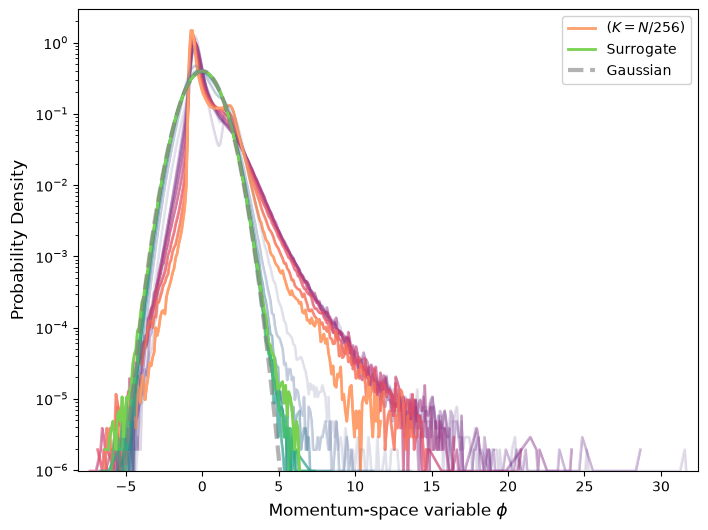

In [6]:
surrogate_array = prg.tools.shuffle_isi(binary_array, data_format='timeseries', random_seed=1)
MS_surrogate = prg.MSVariables(surrogate_array, rg_steps=rg_steps)
MS_surrogate_distribution = prg.momentum_space_distribution(MS_surrogate, bins=bins)

fig = plt.figure(figsize=(8, 6))
prg.plot.plot_momentum_space_distribution(MS_distribution, surrogate_data=MS_surrogate_distribution)
plt.show()

The surrogate (blue to green) collapses onto the Gaussian after only a few steps, while the original data keeps its non-Gaussian shape. A simple way to quantify this is the excess kurtosis of $\phi$, which is zero for a Gaussian:

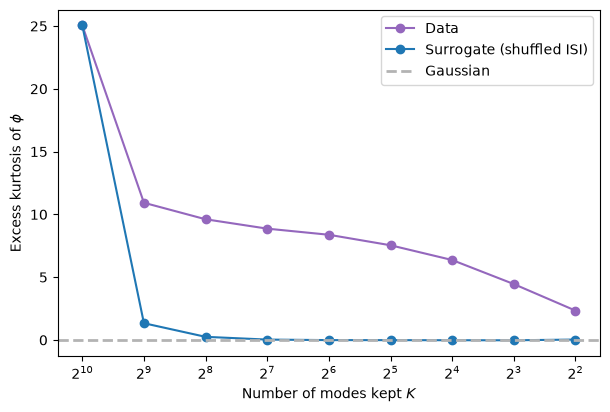

In [7]:
def excess_kurtosis_by_step(ms_variables):
    return [kurtosis(ms_variables.get_MS_variables(k).ravel()) for k in range(ms_variables.rg_steps + 1)]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(MS_variables.cutoffs, excess_kurtosis_by_step(MS_variables), 'o-', color='tab:purple', label='Data')
ax.plot(MS_surrogate.cutoffs, excess_kurtosis_by_step(MS_surrogate), 'o-', color='tab:blue', label='Surrogate (shuffled ISI)')
ax.axhline(0, color='0.7', ls='--', lw=2, label='Gaussian')
ax.set_xscale('log', base=2)
ax.invert_xaxis()
ax.set_xlabel('Number of modes kept $K$')
ax.set_ylabel('Excess kurtosis of $\\phi$')
ax.legend()
plt.show()

### Real space and momentum space side by side

The two coarse-graining schemes look at the same question from different angles: real space builds clusters of $2^k$ correlated neurons and follows the distribution of their summed activity; momentum space keeps the $N/2^k$ most collective modes and follows the distribution of the projected variables. In both cases, a distribution that keeps a non-Gaussian form as we coarse grain is a signature of non-trivial collective behavior.

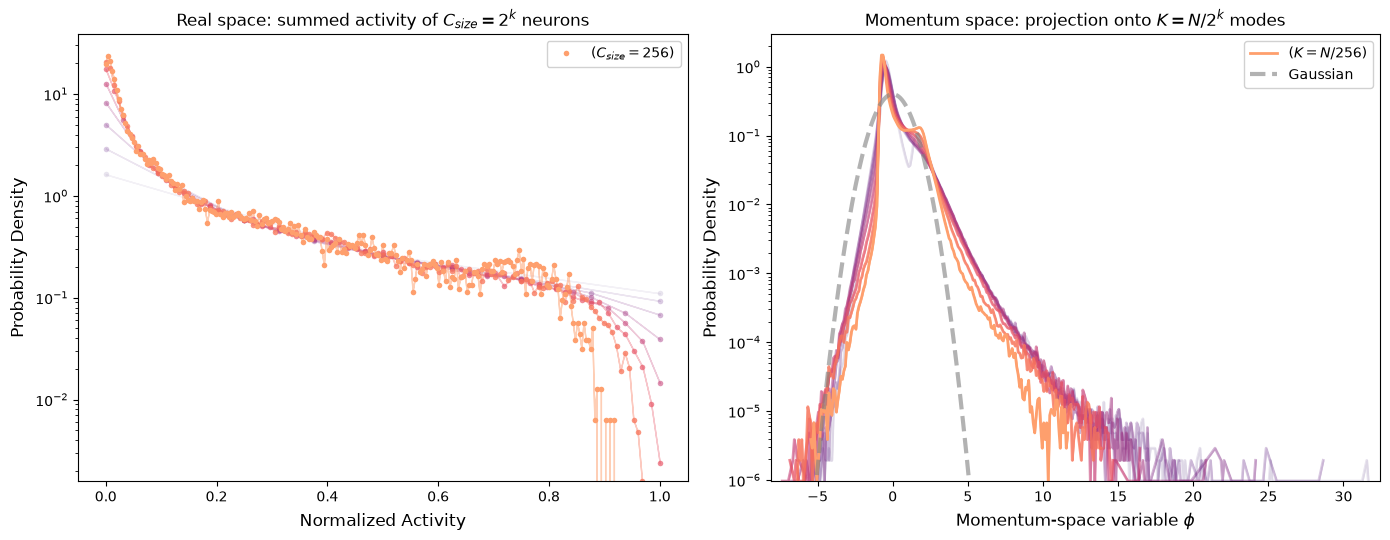

In [8]:
CG_variables = prg.CGVariables(binary_array, cluster_method='pearson', rg_steps=rg_steps)
activity = prg.activity_distribution(CG_variables)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
prg.plot.plot_activity_distribution(activity, ax=axes[0])
axes[0].set_title('Real space: summed activity of $C_{size} = 2^k$ neurons')
prg.plot.plot_momentum_space_distribution(MS_distribution, ax=axes[1])
axes[1].set_title('Momentum space: projection onto $K = N/2^k$ modes')
plt.tight_layout()
plt.show()

### Summary

- `prg.MSVariables(data, rg_steps)` performs the momentum-space coarse graining; `get_MS_variables(k)` returns the $N$ variables built from the $K = N/2^k$ leading principal components.
- `prg.momentum_space_distribution(MS_variables, bins=...)` computes the probability density of those variables at every step, on fixed bins.
- `prg.plot.plot_momentum_space_distribution(...)` plots it against the standard normal reference, with the same styling options (`style_config`, `palette`, `surrogate_data`, ...) as the other plotting functions.

Note that `MSVariables` is not part of the `run_PRG` pipeline: for windowed or batch analyses, loop over your windows and call the functions above. Since the bins are fixed, the resulting densities can be stacked and averaged directly.

---
#### References

1. L. Meshulam, J. L. Gauthier, C. D. Brody, D. W. Tank, and W. Bialek, *Coarse graining, fixed points, and scaling in a large population of neurons*, [Phys. Rev. Lett. **123**, 178103 (2019)](https://doi.org/10.1103/PhysRevLett.123.178103).
2. G. Nicoletti, S. Suweis, and A. Maritan, *Scaling and criticality in a phenomenological renormalization group*, [Phys. Rev. Research **2**, 023144 (2020)](https://journals.aps.org/prresearch/abstract/10.1103/PhysRevResearch.2.023144).
3. M. Schmidt, R. Bakker, K. Shen, G. Bezgin, M. Diesmann, and S. J. van Albada, *A multi-scale layer-resolved spiking network model of resting-state dynamics in macaque visual cortical areas*, [PLoS Comput. Biol. **14**, e1006359 (2018)](https://doi.org/10.1371/journal.pcbi.1006359).